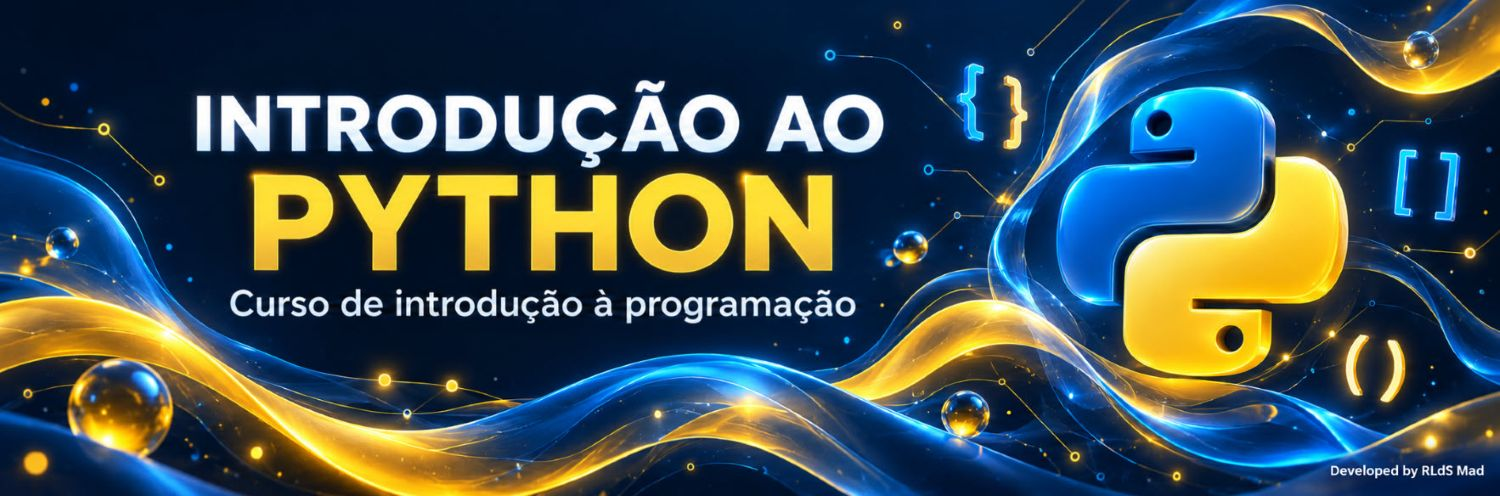

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python_v2/nivel_3_ia/RLdS_N3_02_Caso_Real_Pinguins.ipynb)


# Nível IA · Módulo 2 · Caso real – Estatística descritiva dos pinguins de Palmer
## A análise completa, num conjunto de dados real, em poucas linhas

Nos módulos 1 e 2 resolveste os 12 exercícios da disciplina, primeiro em Python puro e depois com NumPy, pandas e SciPy, e no fim reuniste tudo num módulo, `estatistica.py`. Os exercícios tinham dados pequenos e «arrumados». Neste caso real aplicas **as mesmas ferramentas e as mesmas convenções** a dados recolhidos no terreno, com valores em falta, várias variáveis e grupos.

Os dados são medições de 344 pinguins de três espécies, feitas entre 2007 e 2009 em três ilhas do arquipélago de Palmer, na Antártida, pela equipa da Dra. Kristen Gorman (Palmer Station LTER). Estão em domínio público (licença CC0) e são hoje um dos conjuntos de dados mais usados para ensinar estatística e ciência de dados.

Pelo caminho, vais encontrar uma lição que os exercícios não mostravam: **a distribuição global de uma variável pode esconder grupos com comportamentos muito diferentes**, e isso muda a leitura da média, da assimetria, da curtose e dos *outliers*.

> **Objetivos:** classificar as variáveis de um conjunto de dados real; tratar valores em falta com decisões explícitas; construir tabelas de frequências e de classes com o módulo `estatistica.py`; calcular e interpretar medidas de localização, dispersão e forma com as convenções da disciplina; detetar *outliers* globalmente e por grupo; comparar grupos com `groupby` e gráficos; escrever um pequeno relatório com as conclusões.

**Pré-requisitos:** módulos N3_01 e N3_02 (estatística descritiva em Python puro e com bibliotecas).

| Secção | Tema |
| --- | --- |
| 0. Preparação | bibliotecas e o módulo `estatistica.py` |
| 1. Os dados | origem, variáveis e tipos |
| 2. Qualidade dos dados | valores em falta |
| 3. Variáveis qualitativas | espécies e ilhas |
| 4. Uma variável quantitativa: a massa corporal | classes, localização, dispersão, forma e *outliers* |
| 5. A forma global esconde grupos | a massa por espécie |
| 6. Espécie e sexo | dimorfismo sexual |
| 7. Todas as variáveis em poucas linhas | uma função de resumo |
| 8. Relatório | as conclusões, por escrito |
| 9. Experimenta | três exercícios com solução |


## 0. Preparação

### 0.1 Bibliotecas


In [1]:
# Executar esta célula

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 2)
print(f"NumPy {np.__version__} | pandas {pd.__version__} | seaborn {sns.__version__}")

NumPy 2.5.4 | pandas 3.0.6 | seaborn 0.13.2


### 0.2 O módulo `estatistica.py`

Usamos o módulo que construíste no N3_02 (secção 4.1), com as convenções da disciplina: divisor n − 1, quantis pelo método de Weibull, classes [a ; b[ e quantis em classes por interpolação na ogiva. A célula seguinte volta a gravá-lo, para este notebook não depender de teres o ficheiro na pasta. O código é exatamente o mesmo.


In [2]:
%%writefile estatistica.py
"""estatistica.py – estatística descritiva com as convenções da disciplina.

Convenções: divisor n − 1; quantis pela posição p·(n + 1) (método de Weibull);
classes [a ; b[ com a última fechada; quantis em classes por interpolação na ogiva;
moda em classes Mo = L + h·n_seg/(n_ant + n_seg).
"""
from __future__ import annotations

import math
from dataclasses import dataclass

import numpy as np
import pandas as pd


def sturges(n: int) -> int:
    """Número de classes: 1 + 3,3·log10(n), truncado."""
    return int(1 + 3.3 * math.log10(n))


def quantil(dados, p: float) -> float:
    """Quantil de ordem p pela posição p·(n + 1), com interpolação."""
    return float(np.quantile(dados, p, method="weibull"))


@dataclass
class TabelaFrequencias:
    """Tabela valor/frequência de uma variável discreta."""
    valores: np.ndarray
    freqs: np.ndarray

    def __post_init__(self):
        valores, freqs = np.asarray(self.valores), np.asarray(self.freqs)
        ordem = np.argsort(valores)
        self.valores, self.freqs = valores[ordem], freqs[ordem]

    @classmethod
    def de_dados(cls, dados) -> TabelaFrequencias:
        valores, freqs = np.unique(dados, return_counts=True)
        return cls(valores, freqs)

    @property
    def n(self) -> int:
        return int(self.freqs.sum())

    @property
    def dados(self) -> np.ndarray:
        return np.repeat(self.valores, self.freqs)

    def media(self) -> float:
        return float(np.average(self.valores, weights=self.freqs))

    def variancia(self) -> float:
        return float(self.dados.var(ddof=1))

    def desvio_padrao(self) -> float:
        return math.sqrt(self.variancia())

    def quantil(self, p: float) -> float:
        return quantil(self.dados, p)

    def moda(self) -> list:
        return self.valores[self.freqs == self.freqs.max()].tolist()

    def tabela(self) -> pd.DataFrame:
        n = pd.Series(self.freqs, index=self.valores)
        return pd.DataFrame({"n": n, "N": n.cumsum(), "f": n / self.n, "F": n.cumsum() / self.n})


@dataclass
class TabelaClasses:
    """Tabela de classes [li ; ls[ com as respetivas frequências."""
    limites: np.ndarray
    freqs: np.ndarray

    def __post_init__(self):
        self.limites = np.round(np.asarray(self.limites, dtype=float), 10)
        self.freqs = np.asarray(self.freqs)

    @classmethod
    def de_dados(cls, dados, k: int | None = None, amplitude: float | None = None,
                 inicio: float | None = None) -> TabelaClasses:
        k = k or sturges(len(dados))
        inicio = min(dados) if inicio is None else inicio
        amplitude = amplitude or (max(dados) - inicio) / k
        limites = np.round(inicio + amplitude * np.arange(k + 1), 10)
        return cls(limites, np.histogram(dados, bins=limites)[0])

    @property
    def n(self) -> int:
        return int(self.freqs.sum())

    @property
    def centros(self) -> np.ndarray:
        return (self.limites[:-1] + self.limites[1:]) / 2

    @property
    def acumuladas(self) -> np.ndarray:
        return np.cumsum(self.freqs)

    def media(self) -> float:
        return float(np.average(self.centros, weights=self.freqs))

    def variancia(self) -> float:
        desvios2 = (self.centros - self.media()) ** 2
        return float(np.average(desvios2, weights=self.freqs) * self.n / (self.n - 1))

    def desvio_padrao(self) -> float:
        return math.sqrt(self.variancia())

    def quantil(self, p: float) -> float:
        return float(np.interp(p * self.n, np.concatenate([[0], self.acumuladas]), self.limites))

    def moda(self) -> list:
        n = np.concatenate([[0], self.freqs, [0]])
        h = np.diff(self.limites)
        return [float(self.limites[i] + h[i] * n[i + 2] / (n[i] + n[i + 2]))
                for i in np.flatnonzero(self.freqs == self.freqs.max())]

    def tabela(self) -> pd.DataFrame:
        indice = pd.IntervalIndex.from_breaks(self.limites, closed="left")
        return pd.DataFrame({"c": self.centros, "n": self.freqs, "N": self.acumuladas,
                             "f": self.freqs / self.n, "F": self.acumuladas / self.n}, index=indice)

Writing estatistica.py


In [3]:
# Executar esta célula

import importlib

import estatistica as est

importlib.reload(est)                               # garante a versão acabada de gravar
print("Módulo carregado:", est.__doc__.splitlines()[0])

Módulo carregado: estatistica.py – estatística descritiva com as convenções da disciplina.


Juntamos três funções do N3_02 que o módulo não tem, porque dependem dos critérios de interpretação da disciplina: a classificação do coeficiente de variação, a classificação da forma (Pearson Sk2 e K, com referência 0,263) e os limites dos *outliers* pelo critério do AIQ.


In [4]:
# Executar esta célula

def interpretar_cv(cv: float) -> str:
    return "dispersão baixa" if cv <= 15 else "dispersão moderada" if cv <= 30 else "dispersão elevada"


def classificar(sk: float, k: float) -> str:
    """Classifica a assimetria (Pearson) e a curtose (K, referência 0,263)."""
    assim = "positiva" if sk > 0.05 else "negativa" if sk < -0.05 else "aproximadamente simétrica"
    curt = "leptocúrtica" if k < 0.253 else "platicúrtica" if k > 0.273 else "mesocúrtica"
    return f"assimetria {assim}; {curt}"


def outliers(x, severos: bool = False) -> np.ndarray:
    """Valores fora de [Q1 − c·AIQ ; Q3 + c·AIQ], com c = 1,5 (moderados) ou 3 (severos)."""
    x = np.asarray(x)
    q1, q3 = est.quantil(x, 0.25), est.quantil(x, 0.75)
    c = 3 if severos else 1.5
    return x[(x < q1 - c * (q3 - q1)) | (x > q3 + c * (q3 - q1))]

## 1. Os dados

### 1.1 Carregar

O ficheiro `pinguins_palmer.csv` está na pasta `dados`, ao lado deste notebook. Se não estiver (por exemplo, no Colab), a célula descarrega-o do repositório do curso e, em último caso, do repositório de dados do seaborn.


In [5]:
# Executar esta célula

FONTES = [
    Path("dados/pinguins_palmer.csv"),
    "https://raw.githubusercontent.com/ricardoluizdasilva/mestrado_ai_estudos/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python_v2/nivel_3_ia/dados/pinguins_palmer.csv",
    "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv",
]
for fonte in FONTES:
    try:
        bruto = pd.read_csv(fonte)
        print("Dados lidos de:", fonte)
        break
    except (FileNotFoundError, OSError) as erro:
        print("Não foi possível ler", fonte, "→", type(erro).__name__)
print(bruto.shape)
bruto.head()

Dados lidos de: dados/pinguins_palmer.csv
(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


### 1.2 Traduzir e conhecer as variáveis

Traduzimos os nomes das colunas e as categorias para português. Depois, como no início de cada exercício da disciplina, identificamos a **unidade estatística** e o **tipo de cada variável**.


In [6]:
# Executar esta célula

pinguins = bruto.rename(columns={
    "species": "especie", "island": "ilha", "bill_length_mm": "bico_comp_mm", "bill_depth_mm": "bico_alt_mm",
    "flipper_length_mm": "barbatana_mm", "body_mass_g": "massa_g", "sex": "sexo",
})
pinguins["sexo"] = pinguins["sexo"].map({"MALE": "macho", "FEMALE": "fêmea"})
pinguins.sample(5, random_state=1)

,especie,ilha,bico_comp_mm,bico_alt_mm,barbatana_mm,massa_g,sexo
306,Gentoo,Biscoe,43.4,14.4,218.0,4600.0,fêmea
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,macho
291,Gentoo,Biscoe,46.4,15.6,221.0,5000.0,macho
102,Adelie,Biscoe,37.7,16.0,183.0,3075.0,fêmea
289,Gentoo,Biscoe,50.7,15.0,223.0,5550.0,macho


**Unidade estatística:** um pinguim. **População de interesse:** os pinguins adultos das três espécies que nidificam no arquipélago de Palmer; os 344 são uma **amostra**.

| Variável | Significado | Tipo |
| --- | --- | --- |
| `especie` | Adélia, Barbicha (*Chinstrap*) ou Gentoo | qualitativa nominal |
| `ilha` | Biscoe, Dream ou Torgersen | qualitativa nominal |
| `sexo` | macho ou fêmea | qualitativa nominal |
| `bico_comp_mm` | comprimento do bico (mm) | quantitativa contínua |
| `bico_alt_mm` | altura do bico (mm) | quantitativa contínua |
| `barbatana_mm` | comprimento da barbatana (mm) | quantitativa contínua (registada em mm inteiros) |
| `massa_g` | massa corporal (g) | quantitativa contínua (registada de 25 em 25 g) |


## 2. Qualidade dos dados: valores em falta

Dados reais têm quase sempre valores em falta. A pergunta certa, como no N3_03, é **porque é que faltam**, e a decisão deve ficar registada.


In [7]:
# Executar esta célula

print("Valores em falta por variável:")
print(pinguins.isna().sum().to_string())
print("\nLinhas sem nenhuma medição:")
pinguins[pinguins["massa_g"].isna()]

Valores em falta por variável:
especie          0
ilha             0
bico_comp_mm     2
bico_alt_mm      2
barbatana_mm     2
massa_g          2
sexo            11

Linhas sem nenhuma medição:


,especie,ilha,bico_comp_mm,bico_alt_mm,barbatana_mm,massa_g,sexo
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


Há dois pinguins **sem nenhuma medição** (só se sabe a espécie e a ilha) e mais nove sem o **sexo** registado. Decisões:
- os 2 pinguins sem medições saem da análise: não têm nada para analisar;
- os 9 sem sexo **ficam** em todas as análises que não usam o sexo, e só saem na secção 6. Retirá-los já seria deitar fora medições válidas.


In [8]:
# Executar esta célula

pinguins = pinguins.dropna(subset=["massa_g"]).reset_index(drop=True)
print(f"Ficam {len(pinguins)} pinguins; {pinguins['sexo'].isna().sum()} sem o sexo registado.")

Ficam 342 pinguins; 9 sem o sexo registado.


## 3. Variáveis qualitativas: espécies e ilhas

Numa variável **nominal**, a tabela tem as frequências absolutas (n) e relativas (f), mas **não** as acumuladas (N e F): como as categorias não têm ordem, «acumular até Gentoo» não tem significado. A moda é a única medida de localização que faz sentido.


In [9]:
# Executar esta célula

for variavel in ["especie", "ilha"]:
    contagem = pinguins[variavel].value_counts()
    tabela = pd.DataFrame({"n": contagem, "f (%)": 100 * contagem / contagem.sum()})
    print(f"{variavel}: moda = {contagem.idxmax()}")
    display(tabela.round(1))

especie: moda = Adelie


,n,f (%)
especie,,
Adelie,151,44.2
Gentoo,123,36.0
Chinstrap,68,19.9


ilha: moda = Biscoe


,n,f (%)
ilha,,
Biscoe,167,48.8
Dream,124,36.3
Torgersen,51,14.9


Cruzando as duas variáveis numa **tabela de contingência** aparece uma estrutura importante: as espécies não estão distribuídas por igual pelas ilhas.


ilha,Biscoe,Dream,Torgersen,total
especie,,,,
Adelie,44,56,51,151
Chinstrap,0,68,0,68
Gentoo,123,0,0,123
total,167,124,51,342


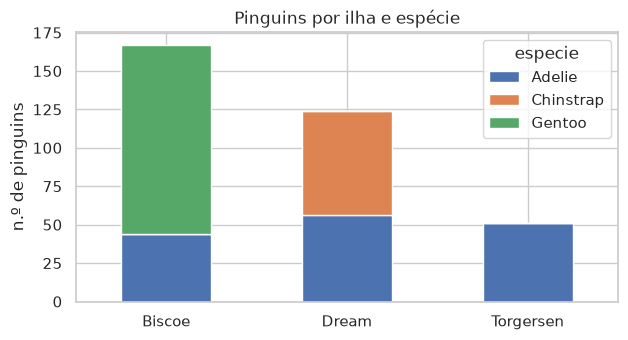

In [10]:
# Executar esta célula

display(pd.crosstab(pinguins["especie"], pinguins["ilha"], margins=True, margins_name="total"))

fig, ax = plt.subplots(figsize=(7, 3.5))
pd.crosstab(pinguins["ilha"], pinguins["especie"]).plot.bar(stacked=True, ax=ax, rot=0)
ax.set(title="Pinguins por ilha e espécie", xlabel="", ylabel="n.º de pinguins")
plt.show()

Os Gentoo só aparecem em Biscoe e os Barbicha só em Dream; só os Adélia estão nas três ilhas. Consequência prática: comparar **ilhas** é, em boa parte, comparar **espécies**. Se Biscoe tiver pinguins mais pesados, pode ser só porque é lá que vivem os Gentoo. É um aviso a ter presente na secção 5.


## 4. Uma variável quantitativa: a massa corporal

Seguimos o mesmo esquema de leitura dos exercícios: tabela de classes → localização → dispersão → forma → *outliers*.

### 4.1 Tabela de classes

Com n = 342, a regra de Sturges dá $k = 1 + 3{,}3 \log_{10} 342 \approx 9{,}4$, ou seja, **9 classes**. A amplitude total é 6300 − 2700 = 3600 g, o que dá classes de 400 g, a começar no mínimo.


In [11]:
# Executar esta célula

massa = pinguins["massa_g"].to_numpy()
k = est.sturges(len(massa))
classes = est.TabelaClasses.de_dados(massa)
print(f"n = {len(massa)} | k = {k} | mínimo = {massa.min():g} | máximo = {massa.max():g} | "
      f"amplitude das classes = {np.diff(classes.limites)[0]:g} g")
classes.tabela().round(3)

n = 342 | k = 9 | mínimo = 2700 | máximo = 6300 | amplitude das classes = 400 g


,c,n,N,f,F
"[2700.0, 3100.0)",2900.0,16,16,0.05,0.05
"[3100.0, 3500.0)",3300.0,55,71,0.16,0.21
"[3500.0, 3900.0)",3700.0,73,144,0.21,0.42
"[3900.0, 4300.0)",4100.0,55,199,0.16,0.58
"[4300.0, 4700.0)",4500.0,44,243,0.13,0.71
"[4700.0, 5100.0)",4900.0,41,284,0.12,0.83
"[5100.0, 5500.0)",5300.0,25,309,0.07,0.90
"[5500.0, 5900.0)",5700.0,27,336,0.08,0.98
"[5900.0, 6300.0)",6100.0,6,342,0.02,1.00


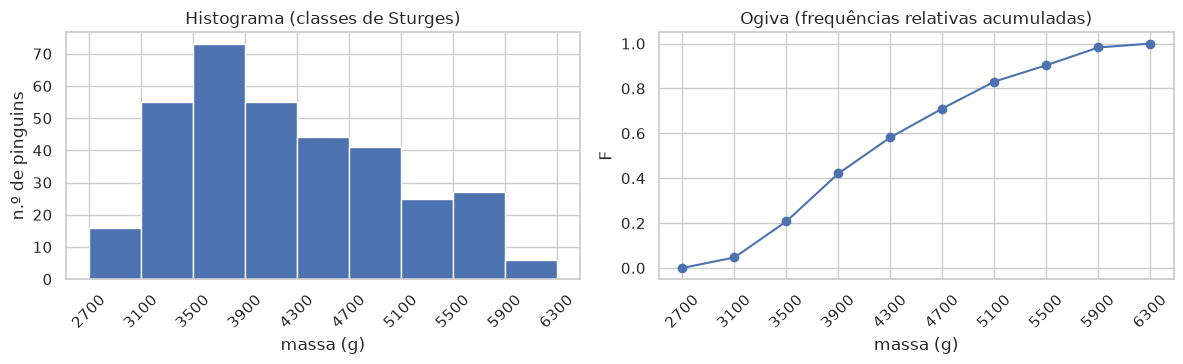

In [12]:
# Executar esta célula

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].hist(massa, bins=classes.limites, edgecolor="white")
axs[0].set(title="Histograma (classes de Sturges)", xlabel="massa (g)", ylabel="n.º de pinguins", xticks=classes.limites)
axs[0].tick_params(axis="x", rotation=45)
axs[1].plot(classes.limites, np.concatenate([[0], classes.acumuladas / classes.n]), marker="o")
axs[1].set(title="Ogiva (frequências relativas acumuladas)", xlabel="massa (g)", ylabel="F", xticks=classes.limites)
axs[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### 4.2 Localização e dispersão

Com os dados individuais, as medidas calculam-se diretamente; com a tabela de classes, pelos pontos médios e por interpolação na ogiva, como nos exercícios 5, 7 e 12. Comparar as duas mostra quanto se perde ao agrupar.


In [13]:
# Executar esta célula

media, mediana, s = massa.mean(), np.median(massa), massa.std(ddof=1)
q1, q3, p10, p90 = (est.quantil(massa, p) for p in (0.25, 0.75, 0.10, 0.90))
valores, contagens = np.unique(massa, return_counts=True)
moda = valores[contagens == contagens.max()]

comparacao = pd.DataFrame({
    "dados individuais": [media, mediana, q1, q3, s, 100 * s / media],
    "tabela de classes": [classes.media(), classes.quantil(0.5), classes.quantil(0.25), classes.quantil(0.75),
                          classes.desvio_padrao(), 100 * classes.desvio_padrao() / classes.media()],
}, index=["média", "mediana", "Q1", "Q3", "desvio-padrão s", "CV (%)"])
display(comparacao.round(2))
print(f"Moda dos dados individuais: {moda.tolist()} (com {contagens.max()} pinguins cada)")
print(f"Moda das classes (fórmula da disciplina): {[round(m, 1) for m in classes.moda()]}")
print(f"Amplitude total = {massa.max() - massa.min():g} g | AIQ = {q3 - q1:g} g | "
      f"CV = {100 * s / media:.1f} % → {interpretar_cv(100 * s / media)}")

,dados individuais,tabela de classes
média,4201.75,4226.32
mediana,4050.00,4096.36
Q1,3550.00,3579.45
Q3,4756.25,4831.71
desvio-padrão s,801.95,815.65
CV (%),19.09,19.30


Moda dos dados individuais: [3800.0] (com 12 pinguins cada)
Moda das classes (fórmula da disciplina): [3700.0]
Amplitude total = 3600 g | AIQ = 1206.25 g | CV = 19.1 % → dispersão moderada


As medidas calculadas a partir das classes ficam próximas das calculadas com os dados individuais, com diferenças de algumas dezenas de gramas: agrupar perde pouca informação com 342 valores. A **moda** dos dados individuais é pouco informativa, porque muitos valores repetem-se poucas vezes; em dados contínuos, a moda das classes é mais útil.

### 4.3 Forma da distribuição


In [14]:
# Executar esta célula

forma = pd.Series({
    "Pearson Sk2 = 3(média − Me)/s": 3 * (media - mediana) / s,
    "Bowley": (q3 + q1 - 2 * mediana) / (q3 - q1),
    "K = (Q3 − Q1)/(2(P90 − P10)), ref. 0,263": (q3 - q1) / (2 * (p90 - p10)),
    "g1 (momentos, ref. 0)": stats.skew(massa),
    "β2 (momentos, ref. 3)": stats.kurtosis(massa, fisher=False),
})
print(forma.round(3).to_string())
print("→", classificar(forma.iloc[0], forma.iloc[2]))

Pearson Sk2 = 3(média − Me)/s               0.57
Bowley                                      0.17
K = (Q3 − Q1)/(2(P90 − P10)), ref. 0,263    0.28
g1 (momentos, ref. 0)                       0.47
β2 (momentos, ref. 3)                       2.27
→ assimetria positiva; platicúrtica


Todos os coeficientes concordam: **assimetria positiva** (a média está acima da mediana; há uma cauda para os pinguins mais pesados) e distribuição **platicúrtica** (K acima de 0,263 e β₂ abaixo de 3): mais «achatada» do que a normal. O histograma confirma: não tem um pico bem definido, mas um patamar largo.

### 4.4 *Outliers*


Limites moderados: [1740.62 ; 6565.62] g → outliers: nenhum


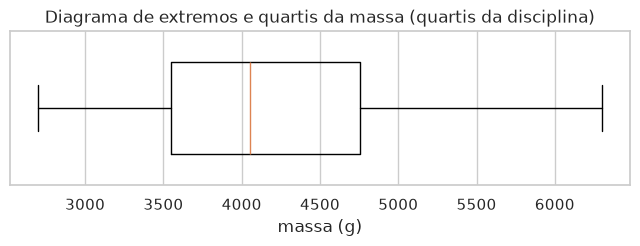

In [15]:
# Executar esta célula

aiq = q3 - q1
print(f"Limites moderados: [{q1 - 1.5 * aiq:g} ; {q3 + 1.5 * aiq:g}] g → outliers: {outliers(massa).tolist() or 'nenhum'}")

dentro = massa[(massa >= q1 - 1.5 * aiq) & (massa <= q3 + 1.5 * aiq)]
caixa = {"med": mediana, "q1": q1, "q3": q3, "whislo": dentro.min(), "whishi": dentro.max(), "fliers": outliers(massa)}
fig, ax = plt.subplots(figsize=(8, 2))
try:
    ax.bxp([caixa], orientation="horizontal", widths=0.6)       # matplotlib 3.10 ou mais recente
except TypeError:
    ax.bxp([caixa], vert=False, widths=0.6)                     # versões anteriores
ax.set(title="Diagrama de extremos e quartis da massa (quartis da disciplina)", xlabel="massa (g)", yticks=[])
plt.show()

Não há *outliers*. Até aqui, a leitura seria: «a massa dos pinguins tem assimetria positiva, é platicúrtica e não tem valores atípicos». A secção seguinte mostra que esta leitura está **incompleta**.


## 5. A forma global esconde grupos

### 5.1 A massa por espécie

Desenhamos o mesmo histograma, mas agora com uma cor por espécie:


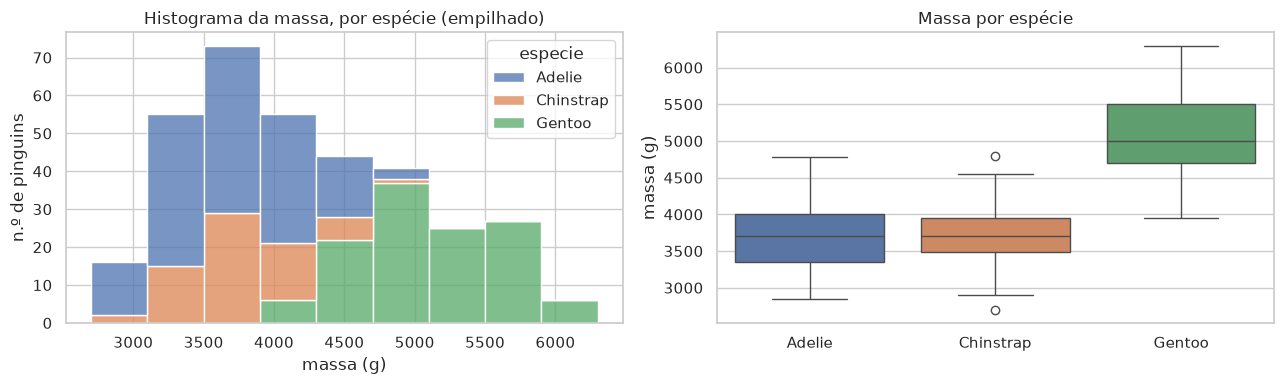

In [16]:
# Executar esta célula

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(pinguins, x="massa_g", hue="especie", bins=classes.limites, multiple="stack", ax=axs[0])
axs[0].set(title="Histograma da massa, por espécie (empilhado)", xlabel="massa (g)", ylabel="n.º de pinguins")
sns.boxplot(pinguins, x="especie", y="massa_g", hue="especie", ax=axs[1], whis=1.5)
axs[1].set(title="Massa por espécie", xlabel="", ylabel="massa (g)")
plt.tight_layout()
plt.show()

(Os diagramas do seaborn calculam os quartis pelo método linear, e não pelo da disciplina; para comparar grupos visualmente, a diferença é desprezável. Os valores exatos estão na tabela da secção 5.2.)

A «distribuição da massa» é, na verdade, a **soma de duas populações**: os Adélia e os Barbicha, com massas parecidas, à volta dos 3700 g, e os Gentoo, muito mais pesados, à volta dos 5000 g. A assimetria positiva e o achatamento da secção 4.3 não descrevem nenhum pinguim real: são o efeito de **misturar** grupos diferentes.

### 5.2 Medidas por espécie

O `groupby` (N3_02, exercício 11) calcula as mesmas medidas para cada espécie. Para os quartis com o método da disciplina, passamos a nossa função ao `agg`.


In [17]:
# Executar esta célula

def q1_disc(x):
    return est.quantil(x, 0.25)


def q3_disc(x):
    return est.quantil(x, 0.75)


def sk2(x):
    return 3 * (x.mean() - x.median()) / x.std()


def k_perc(x):
    return (est.quantil(x, .75) - est.quantil(x, .25)) / (2 * (est.quantil(x, .9) - est.quantil(x, .1)))


por_especie = pinguins.groupby("especie")["massa_g"].agg(
    n="size", media="mean", mediana="median", s="std", Q1=q1_disc, Q3=q3_disc, Sk2=sk2, K=k_perc)
por_especie["CV (%)"] = 100 * por_especie["s"] / por_especie["media"]
por_especie["outliers"] = pinguins.groupby("especie")["massa_g"].agg(lambda x: outliers(x).tolist())
display(por_especie.round(2))
for especie, linha in por_especie.iterrows():
    print(f"{especie:<10} {classificar(linha['Sk2'], linha['K'])}; CV {linha['CV (%)']:.1f} % → {interpretar_cv(linha['CV (%)'])}")

,n,media,mediana,s,Q1,Q3,Sk2,K,CV (%),outliers
especie,,,,,,,,,,
Adelie,151,3700.66,3700.0,458.57,3350.0,4000.0,0.00,0.26,12.39,[]
Chinstrap,68,3733.09,3700.0,384.34,3462.5,3950.0,0.26,0.24,10.30,"[4800.0, 2700.0]"
Gentoo,123,5076.02,5000.0,504.12,4700.0,5500.0,0.45,0.30,9.93,[]


Adelie     assimetria aproximadamente simétrica; mesocúrtica; CV 12.4 % → dispersão baixa
Chinstrap  assimetria positiva; leptocúrtica; CV 10.3 % → dispersão baixa
Gentoo     assimetria positiva; platicúrtica; CV 9.9 % → dispersão baixa


Dentro de cada espécie, a leitura muda:
- a **assimetria** diminui em todas as espécies em relação ao conjunto (Sk2 ≈ 0,57): os Adélia ficam simétricos, os Barbicha com uma assimetria positiva pequena e os Gentoo um pouco menos assimétricos do que o conjunto. Parte da assimetria global vinha da mistura;
- a **curtose** também muda: cada espécie tem a sua classificação, e nenhuma coincide necessariamente com a do conjunto;
- a **dispersão** é mais baixa: o CV de cada espécie fica entre 10 e 12 %, contra 19 % no conjunto, porque a diferença **entre** espécies deixou de contar como variabilidade;
- aparecem ***outliers*** que a análise global não via: dois Barbicha com massas fora do habitual **para a sua espécie**, embora perfeitamente normais para um pinguim qualquer.

> **Lição:** antes de interpretar a forma de uma distribuição, pergunta se os dados misturam grupos diferentes. Um histograma com dois «montes» (bimodal) ou muito achatado é muitas vezes o sinal. É o mesmo cuidado que, no N3_03, levou ao paradoxo de Simpson.


## 6. Espécie e sexo: o dimorfismo sexual

Dentro de cada espécie há ainda outro grupo: o **sexo**. Aqui retiramos os 9 pinguins sem sexo registado (secção 2).


mean            std         size      
sexo        fêmea   macho  fêmea  macho fêmea macho
especie                                            
Adelie     3369.0  4043.0  269.0  347.0    73    73
Chinstrap  3527.0  3939.0  285.0  362.0    34    34
Gentoo     4680.0  5485.0  282.0  313.0    58    61

Diferença média macho − fêmea (g): {'Adelie': 675.0, 'Chinstrap': 412.0, 'Gentoo': 805.0}
Em percentagem da média das fêmeas: {'Adelie': 20.0, 'Chinstrap': 11.7, 'Gentoo': 17.2}


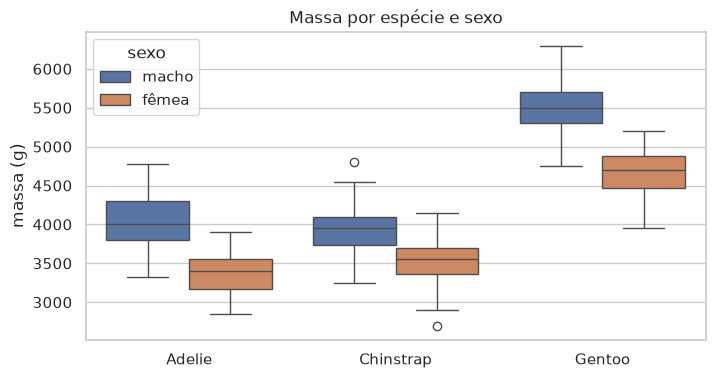

In [18]:
# Executar esta célula

com_sexo = pinguins.dropna(subset=["sexo"])
tabela_sexo = com_sexo.pivot_table(index="especie", columns="sexo", values="massa_g", aggfunc=["mean", "std", "size"])
display(tabela_sexo.round(0))

diferenca = tabela_sexo[("mean", "macho")] - tabela_sexo[("mean", "fêmea")]
print("Diferença média macho − fêmea (g):", diferenca.round(0).to_dict())
print("Em percentagem da média das fêmeas:", (100 * diferenca / tabela_sexo[("mean", "fêmea")]).round(1).to_dict())

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(com_sexo, x="especie", y="massa_g", hue="sexo", ax=ax)
ax.set(title="Massa por espécie e sexo", xlabel="", ylabel="massa (g)")
plt.show()

Em todas as espécies, os machos são mais pesados do que as fêmeas: é o **dimorfismo sexual**, mais acentuado nos Adélia e nos Gentoo do que nos Barbicha. O desvio-padrão dentro de cada combinação espécie × sexo é ainda menor do que dentro de cada espécie: cada vez que separamos por um grupo com significado biológico, uma parte da «variabilidade» revela-se como **diferença entre grupos**.


## 7. Todas as variáveis em poucas linhas

Com o módulo e as funções acima, a análise completa de **qualquer** variável quantitativa cabe numa função. Aplicamo-la às quatro medições, primeiro para o conjunto e depois por espécie.


In [19]:
# Executar esta célula

def resumo(x) -> pd.Series:
    """Resumo de uma variável quantitativa com as convenções da disciplina."""
    x = np.asarray(x, dtype=float)
    q1, me, q3, p10, p90 = (est.quantil(x, p) for p in (0.25, 0.5, 0.75, 0.1, 0.9))
    m, s = x.mean(), x.std(ddof=1)
    return pd.Series({"n": len(x), "média": m, "mediana": me, "s": s, "CV (%)": 100 * s / m,
                      "Q1": q1, "Q3": q3, "Sk2": 3 * (m - me) / s, "K": (q3 - q1) / (2 * (p90 - p10)),
                      "outliers": len(outliers(x))})


medicoes = ["bico_comp_mm", "bico_alt_mm", "barbatana_mm", "massa_g"]
print("Conjunto dos pinguins:")
display(pinguins[medicoes].apply(resumo).T.round(2))
print("Por espécie:")
display(pinguins.groupby("especie")[medicoes].apply(lambda g: g.apply(resumo).T).round(2))

Conjunto dos pinguins:


,n,média,mediana,s,CV (%),Q1,Q3,Sk2,K,outliers
bico_comp_mm,342.0,43.92,44.45,5.46,12.43,39.20,48.50,-0.29,0.33,0.0
bico_alt_mm,342.0,17.15,17.30,1.97,11.51,15.58,18.70,-0.23,0.30,0.0
barbatana_mm,342.0,200.92,197.00,14.06,7.00,190.00,213.25,0.84,0.32,0.0
massa_g,342.0,4201.75,4050.00,801.95,19.09,3550.00,4756.25,0.57,0.28,0.0


Por espécie:


n    média  mediana       s  CV (%)       Q1  \
especie                                                                    
Adelie    bico_comp_mm  151.0    38.79    38.80    2.66    6.87    36.70   
          bico_alt_mm   151.0    18.35    18.40    1.22    6.63    17.50   
          barbatana_mm  151.0   189.95   190.00    6.54    3.44   186.00   
          massa_g       151.0  3700.66  3700.00  458.57   12.39  3350.00   
Chinstrap bico_comp_mm   68.0    48.83    49.55    3.34    6.84    46.25   
          bico_alt_mm    68.0    18.42    18.45    1.14    6.16    17.50   
          barbatana_mm   68.0   195.82   196.00    7.13    3.64   191.00   
          massa_g        68.0  3733.09  3700.00  384.34   10.30  3462.50   
Gentoo    bico_comp_mm  123.0    47.50    47.30    3.08    6.49    45.30   
          bico_alt_mm   123.0    14.98    15.00    0.98    6.55    14.20   
          barbatana_mm  123.0   217.19   216.00    6.48    2.99   212.00   
          massa_g       123.0  5076.02  5000.00  504.12    9.93  4700.00   

                             Q3   Sk2     K  outliers  
especie                                                
Adelie    bico_comp_mm    40.80 -0.01  0.31       0.0  
          bico_alt_mm     19.00 -0.13  0.24       1.0  
          barbatana_mm   195.00 -0.02  0.26       2.0  
          massa_g       4000.00  0.00  0.26       0.0  
Chinstrap bico_comp_mm    51.22 -0.64  0.34       0.0  
          bico_alt_mm     19.40 -0.08  0.30       0.0  
          barbatana_mm   201.00 -0.07  0.28       0.0  
          massa_g       3950.00  0.26  0.24       2.0  
Gentoo    bico_comp_mm    49.60  0.20  0.29       1.0  
          bico_alt_mm     15.70 -0.05  0.29       0.0  
          barbatana_mm   221.00  0.55  0.24       0.0  
          massa_g       5500.00  0.45  0.30       0.0

Duas tabelas, quatro variáveis, três espécies, todas com as convenções da disciplina. É este o ganho de ter organizado o código num módulo e em funções: a análise de um conjunto de dados novo passa a ser uma questão de minutos.

Repara também no gráfico de pares, que mostra as quatro variáveis duas a duas: cada espécie forma uma «nuvem» separada, sobretudo nas combinações com a altura do bico.


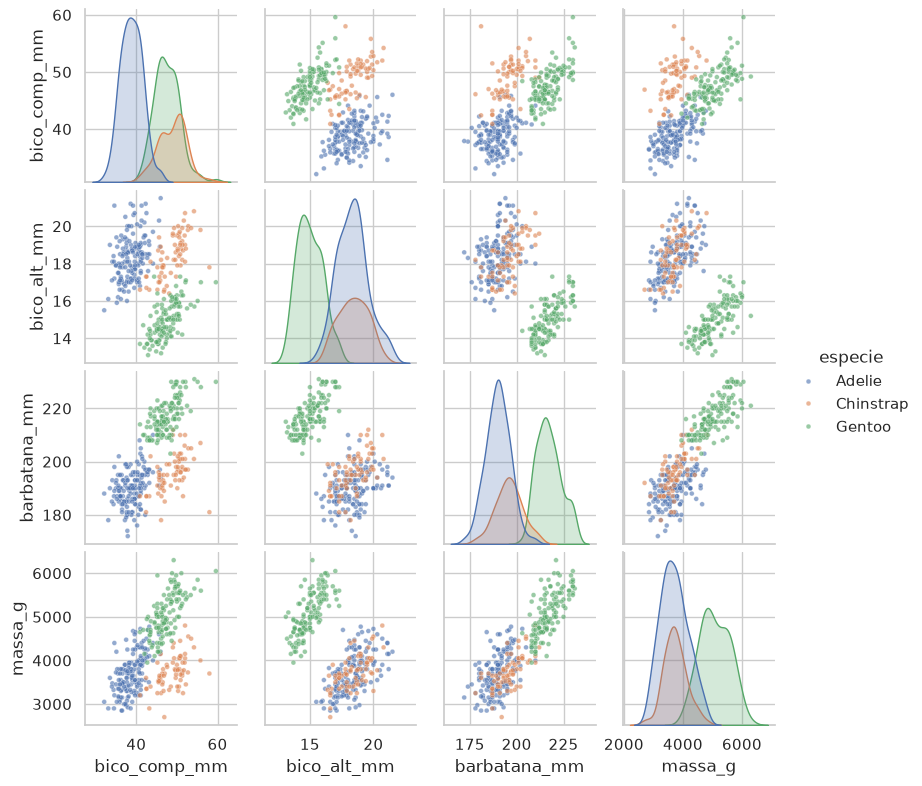

In [20]:
# Executar esta célula

sns.pairplot(pinguins[medicoes + ["especie"]], hue="especie", height=2, plot_kws={"s": 12, "alpha": 0.6})
plt.show()

## 8. Relatório

O último passo de qualquer análise é **comunicar** as conclusões a quem não viu o código. A célula seguinte gera um relatório curto a partir dos valores calculados, para que os números do texto estejam sempre certos (se os dados mudarem, o relatório acompanha).


In [21]:
# Executar esta célula

g = por_especie
pt = lambda x, casas=0: f"{x:,.{casas}f}".replace(",", " ").replace(".", ",")      # números à portuguesa
com_outliers = {esp: o for esp, o in g["outliers"].items() if o}
cv_total = 100 * s / media
rel = f"""
RELATÓRIO – Massa corporal dos pinguins de Palmer (n = {len(massa)})

1. Dados. {len(bruto)} pinguins de 3 espécies; 2 sem medições foram excluídos e {pinguins['sexo'].isna().sum()} sem sexo
   registado só foram excluídos da análise por sexo.

2. Conjunto. A massa média é de {pt(media)} g (mediana {pt(mediana)} g; s = {pt(s)} g; CV = {pt(cv_total, 1)} %,
   {interpretar_cv(cv_total)}). A distribuição tem {classificar(forma.iloc[0], forma.iloc[2]).replace('; ', ' e é ')}, sem outliers.

3. Espécies. A forma global resulta da mistura de grupos: Adélia ({pt(g.loc['Adelie', 'media'])} g) e Barbicha
   ({pt(g.loc['Chinstrap', 'media'])} g) têm massas semelhantes; os Gentoo ({pt(g.loc['Gentoo', 'media'])} g) são cerca de
   {pt(g.loc['Gentoo', 'media'] - g.loc['Adelie', 'media'])} g mais pesados. Dentro de cada espécie, o CV fica entre
   {pt(g['CV (%)'].min())} e {pt(g['CV (%)'].max())} % e a assimetria é menor do que no conjunto.
   Outliers dentro das espécies, invisíveis na análise global: {com_outliers or 'nenhum'}.

4. Sexo. Em todas as espécies os machos são mais pesados (diferença média de {pt(diferenca.min())} a {pt(diferenca.max())} g).

5. Recomendação. Resumir e comparar a massa sempre por espécie (e, se possível, por sexo);
   as medidas do conjunto não descrevem nenhum grupo real.
"""
print(rel)


RELATÓRIO – Massa corporal dos pinguins de Palmer (n = 342)

1. Dados. 344 pinguins de 3 espécies; 2 sem medições foram excluídos e 9 sem sexo
   registado só foram excluídos da análise por sexo.

2. Conjunto. A massa média é de 4 202 g (mediana 4 050 g; s = 802 g; CV = 19,1 %,
   dispersão moderada). A distribuição tem assimetria positiva e é platicúrtica, sem outliers.

3. Espécies. A forma global resulta da mistura de grupos: Adélia (3 701 g) e Barbicha
   (3 733 g) têm massas semelhantes; os Gentoo (5 076 g) são cerca de
   1 375 g mais pesados. Dentro de cada espécie, o CV fica entre
   10 e 12 % e a assimetria é menor do que no conjunto.
   Outliers dentro das espécies, invisíveis na análise global: {'Chinstrap': [4800.0, 2700.0]}.

4. Sexo. Em todas as espécies os machos são mais pesados (diferença média de 412 a 805 g).

5. Recomendação. Resumir e comparar a massa sempre por espécie (e, se possível, por sexo);
   as medidas do conjunto não descrevem nenhum grupo real.



## 9. Experimenta

### Exercício 1 – O comprimento do bico

Repete a análise da secção 5.2 para o **comprimento do bico** (`bico_comp_mm`): medidas por espécie, classificação da forma e *outliers*. Que espécie tem o bico mais comprido? Os Adélia e os Barbicha, que tinham massas parecidas, também têm bicos parecidos?


In [22]:
# Executar esta célula

# Escreve aqui o código do exercício 1

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
bico = pinguins.groupby("especie")["bico_comp_mm"].agg(
    n="size", media="mean", mediana="median", s="std", Q1=q1_disc, Q3=q3_disc, Sk2=sk2, K=k_perc)
bico["outliers"] = pinguins.groupby("especie")["bico_comp_mm"].agg(lambda x: outliers(x).tolist())
display(bico.round(2))

sns.boxplot(pinguins, x="especie", y="bico_comp_mm", hue="especie")
plt.ylabel("comprimento do bico (mm)")
plt.show()
# Os Barbicha têm o bico mais comprido (média perto da dos Gentoo) e os Adélia o mais curto:
# as duas espécies com massas parecidas distinguem-se pelo bico. É por isso que, no pairplot,
# as três espécies se separam bem quando se combina o bico com a massa ou a barbatana.
```

</details>


### Exercício 2 – *Z-scores* ou AIQ?

O N3_02 (secção 5.3) apresentou outro critério para *outliers*: os valores com |z| > 3, em que $z = (x - \bar{x})/s$. Aplica os dois critérios (AIQ moderado e |z| > 3) à **altura do bico** de cada espécie e compara quantos valores cada um assinala.


In [23]:
# Executar esta célula

# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for especie, grupo in pinguins.groupby("especie"):
    x = grupo["bico_alt_mm"].to_numpy()
    z = stats.zscore(x, ddof=1)
    print(f"{especie:<10} AIQ: {outliers(x).tolist() or 'nenhum'} | |z| > 3: {x[np.abs(z) > 3].tolist() or 'nenhum'}")
# O critério |z| > 3 é mais exigente: com distribuições aproximadamente normais, só assinala
# valores muito extremos. O AIQ moderado (1,5) assinala mais casos, e não depende da média
# nem do desvio-padrão, que são eles próprios influenciados pelos outliers.
```

</details>


### Exercício 3 – Classes à medida

A regra de Sturges dá classes com limites «estranhos» quando o mínimo e a amplitude não são redondos. Constrói a tabela de classes do **comprimento da barbatana** com classes de 10 mm a começar em 170 mm (usa `est.TabelaClasses.de_dados(x, k=..., amplitude=10, inicio=170)`, escolhendo o k que cubra o máximo), mostra a tabela e calcula a mediana e os quartis pela tabela e pelos dados individuais.


In [24]:
# Executar esta célula

# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
barbatana = pinguins["barbatana_mm"].to_numpy()
k = int(np.ceil((barbatana.max() - 170) / 10)) + (1 if (barbatana.max() - 170) % 10 == 0 else 0)
t = est.TabelaClasses.de_dados(barbatana, k=k, amplitude=10, inicio=170)
print(f"mínimo {barbatana.min():g} | máximo {barbatana.max():g} | k = {k}")
display(t.tabela().round(3))
for nome, p in [("Q1", .25), ("mediana", .5), ("Q3", .75)]:
    print(f"{nome:<8} tabela {t.quantil(p):7.2f} | dados individuais {est.quantil(barbatana, p):7.2f}")
```

</details>


## Verifica o que aprendeste

1. Porque é que, numa variável nominal como a espécie, a tabela de frequências não tem as colunas N e F?
2. Que decisão se tomou sobre os pinguins sem sexo registado, e porque não foram retirados logo no início?
3. Porque é que comparar as ilhas é, em boa parte, comparar as espécies?
4. A massa do conjunto tem assimetria positiva e é platicúrtica. Porque é que essa leitura engana?
5. Porque é que o CV de cada espécie é menor do que o CV do conjunto?
6. Como é possível haver *outliers* dentro das espécies e nenhum no conjunto?
7. Que vantagem tem gerar o relatório a partir dos valores calculados, em vez de escrever os números à mão?

<details>
<summary><b>Ver respostas</b></summary>

1. Porque as categorias não têm ordem: acumular frequências «até uma espécie» não tem significado.
2. Ficaram em todas as análises que não usam o sexo, e só saíram na secção 6. Retirá-los logo seria perder medições válidas de massa, bico e barbatana.
3. Porque os Gentoo só vivem em Biscoe e os Barbicha só em Dream: uma diferença entre ilhas pode ser apenas uma diferença entre espécies.
4. Porque resulta da mistura de duas populações com massas diferentes (Adélia e Barbicha de um lado, Gentoo do outro). Nenhuma espécie, sozinha, tem essa forma.
5. Porque, no conjunto, a diferença entre as médias das espécies também conta como dispersão. Dentro de cada espécie, só fica a variação entre pinguins semelhantes.
6. Porque os limites do conjunto são largos (incluem as massas das três espécies). Um Barbicha muito pesado para a sua espécie fica dentro dos limites gerais, mas fora dos limites calculados só com os Barbicha.
7. Os números do texto ficam sempre certos e atualizam-se se os dados ou os cálculos mudarem; não há erros de cópia.

</details>

## Leitura recomendada

- Gorman, K. B., Williams, T. D. e Fraser, W. R. (2014). «[Ecological sexual dimorphism and environmental variability within a community of Antarctic penguins (genus *Pygoscelis*)](https://doi.org/10.1371/journal.pone.0090081)». *PLOS ONE*, 9(3), e90081. O estudo original de onde vêm os dados.
- Horst, A. M., Hill, A. P. e Gorman, K. B. (2020). *[palmerpenguins: Palmer Archipelago (Antarctica) penguin data](https://allisonhorst.github.io/palmerpenguins/)*. O pacote que tornou os dados públicos (licença CC0).
- Reis, E. (2009). *Estatística Descritiva* (7.ª ed.). Lisboa: Edições Sílabo.
- Curto, J. D. e Pinto, J. (2014). *Estatística para Economia e Gestão*. Lisboa: Edições Sílabo.
- Downey, A. B. (2025). *[Think Stats: Exploratory Data Analysis in Python](https://www.oreilly.com/library/view/think-stats-3rd/9781098190248/)* (3.ª ed.). Sebastopol: O'Reilly Media.
- **Módulos relacionados:** N3_01 e N3_02 (estatística descritiva) e N3_03 (o processo KDD e o paradoxo de Simpson).
